In [1]:
import math
import torch
import torch.nn as nn

In [2]:
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- data: 2D two moons, normalized ----------
def make_moons(n, noise=0.05):
    n1, n2 = n // 2, n - n // 2
    t1 = torch.rand(n1) * math.pi
    t2 = torch.rand(n2) * math.pi
    a = torch.stack([torch.cos(t1), torch.sin(t1)], 1)
    b = torch.stack([1 - torch.cos(t2), 0.5 - torch.sin(t2)], 1)
    x = torch.cat([a, b]) + noise * torch.randn(n, 2)
    return (x - x.mean(0)) / x.std(0)

In [3]:
# ---------- noise schedule ----------
T = 200
betas = torch.linspace(1e-4, 0.05, T, device=device)
alphas = 1.0 - betas
abar = torch.cumprod(alphas, dim=0)          # \bar{alpha}_t

In [4]:
# ---------- model: predicts the noise eps from (x_t, t) ----------
class TimeEmbed(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.dim = dim

    def forward(self, t):                    # t: (B,) integer steps
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        ang = t[:, None].float() * freqs[None]
        return torch.cat([ang.sin(), ang.cos()], dim=-1)

class EpsNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.temb = TimeEmbed(64)
        self.net = nn.Sequential(
            nn.Linear(2 + 64, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, self.temb(t)], dim=-1))

In [5]:
model = EpsNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

In [8]:
# ---------- training ----------
for step in range(1, 6001):
    x0 = make_moons(256).to(device)
    t = torch.randint(0, T, (x0.shape[0],), device=device)
    eps = torch.randn_like(x0)
    ab = abar[t][:, None]
    xt = ab.sqrt() * x0 + (1 - ab).sqrt() * eps     # forward process in closed form
    loss = ((model(xt, t) - eps) ** 2).mean()       # simple DDPM loss
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 1000 == 0:
        print(f"step {step}  loss {loss.item():.4f}")

step 1000  loss 0.3459
step 2000  loss 0.3139
step 3000  loss 0.2910
step 4000  loss 0.3052
step 5000  loss 0.3712
step 6000  loss 0.3107


In [13]:
x0.shape

torch.Size([256, 2])

In [16]:
eps 

tensor([[-0.1182, -1.1728],
        [ 1.4044,  0.8119],
        [ 1.0856, -0.0676],
        [ 0.9648, -0.3668],
        [-0.1525, -1.0144],
        [-0.7626, -0.1615],
        [-0.6156,  0.4285],
        [-0.4900,  0.2157],
        [-0.7961,  0.1991],
        [-1.7979, -1.1982],
        [ 0.4466, -0.9225],
        [-1.9037,  0.0538],
        [-0.8259,  0.5425],
        [ 1.0375, -0.5423],
        [ 1.7991,  0.9001],
        [ 1.1454, -2.1770],
        [ 0.8981,  1.1862],
        [-1.0136,  2.1486],
        [ 0.4315, -1.1549],
        [ 1.6397, -0.5858],
        [-0.8572,  0.1934],
        [ 1.1047, -0.1308],
        [ 1.6264, -0.4881],
        [-0.3648,  0.6210],
        [ 1.4273,  0.6179],
        [-0.9231,  0.7630],
        [-0.1324, -0.3777],
        [-0.0375, -0.7103],
        [-0.9008,  0.3711],
        [-1.3256, -0.7444],
        [ 0.6185, -0.7024],
        [ 0.9489,  0.3646],
        [ 0.7692,  0.3019],
        [-0.4747, -0.8521],
        [ 1.9654,  0.8840],
        [-0.4556,  1

In [9]:
# ---------- sampling (reverse process) ----------
@torch.no_grad()
def sample(n):
    x = torch.randn(n, 2, device=device)
    for t in reversed(range(T)):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps_hat = model(x, tt)
        mean = (x - betas[t] / (1 - abar[t]).sqrt() * eps_hat) / alphas[t].sqrt()
        x = mean + betas[t].sqrt() * torch.randn_like(x) if t > 0 else mean
    return x

In [10]:
samples = sample(2000).cpu()
print("sample mean", samples.mean(0), "std", samples.std(0))

sample mean tensor([ 0.1231, -0.0556]) std tensor([1.0200, 1.0162])


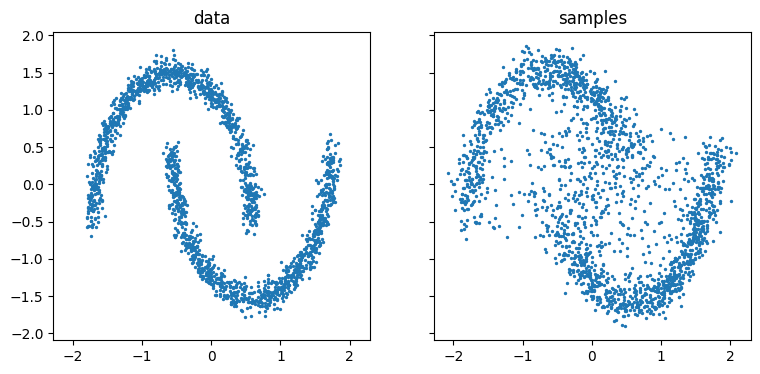

In [11]:
try:
    import matplotlib.pyplot as plt
    real = make_moons(2000)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
    ax[0].scatter(*real.T, s=2); ax[0].set_title("data")
    ax[1].scatter(*samples.T, s=2); ax[1].set_title("samples")
    plt.savefig("diffusion_samples.png", dpi=120)
except ImportError:
    pass